# Model Comparison

This notebook compares three different models using the same engineered features and dataset splits:
1. Logistic Regression
2. LightGBM
3. Neural Network

My goal here isn't to chase a high competition score, but to look at how and why the performance shifts across these three architectures. Since credit risk models need to be presented to regulators, I want to evaluate them based on risk separation, output probability distributions, and interpretability.

Because the data is imbalanced with an 8% default rate, I am ignoring standard accuracy and focusing on ROC-AUC. I also want to test how different imbalance handling techniques affect the final performance metrics across the models.



In [1]:
import sys
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.metrics import roc_auc_score, roc_curve, brier_score_loss, RocCurveDisplay
from sklearn.calibration import CalibrationDisplay

from data_engineering import build_dataset,prepare_train_test
from lr_model import fit_logistic,predict_logistic,coefficient_table
from lightgbm_model import fit_lightgbm,predict_lightgbm,feature_importance_table, transform_lightgbm_data
from nn_model import fit_neural_network,predict_neural_network

In [2]:
folder = "home-credit-default-risk/"

application_train = pd.read_csv(folder + "application_train.csv")
bureau = pd.read_csv(folder + "bureau.csv")
previous_application = pd.read_csv(folder + "previous_application.csv")
installments = pd.read_csv(folder + "installments_payments.csv")

In [3]:
df = build_dataset(application_train,bureau,previous_application,installments)

X_train, X_test, y_train, y_test, id_train, id_test = prepare_train_test(df)

print("Train shape:", X_train.shape)
print("Test shape:", X_test.shape)
print("Train default rate:", round(y_train.mean(), 4))
print("Test default rate:", round(y_test.mean(), 4))

Train: (246008, 144) | Test: (61503, 144)
Train default rate: 0.0807 | Test default rate: 0.0807
Missing indicators: 44
Train shape: (246008, 144)
Test shape: (61503, 144)
Train default rate: 0.0807
Test default rate: 0.0807


### Common dataset

All three models use the same engineered dataset and Train/Test population.

The model-specific files only change the preprocessing and estimation method required by each model. This makes the comparison easier to interpret because the underlying information is held broadly constant.

In [4]:
def evaluate_model(y_train, p_train, y_test, p_test):
    train_auc = roc_auc_score(y_train, p_train)
    test_auc = roc_auc_score(y_test, p_test)
    fpr, tpr, _ = roc_curve(y_test, p_test)
    
    return {"Train AUC": train_auc,
            "Test AUC": test_auc,
            "Test KS": np.max(tpr - fpr),
            "Test Brier": brier_score_loss(y_test, p_test)}

## Logistic Regression

Logistic Regression provides our simplest and most directly interpretable benchmark. Numerical variables are standardised and categorical variables are one-hot encoded before estimation. 

The model estimates the log-odds of default as a linear combination of the predictors. This linear structure makes the model incredibly easy to interpret because every feature gets a specific coefficient. The direction of the coefficient tells us if a feature increases or decreases risk, and the absolute size of the weight shows its relative impact on the log-odds of default. This transparency makes the baseline highly interpretable and straightforward to explain to a regulator before testing more complex models.


In [5]:
lr_model = fit_logistic(X_train, y_train)
p_train_lr = predict_logistic(lr_model, X_train)
p_test_lr = predict_logistic(lr_model, X_test)

lr_results = evaluate_model(y_train, p_train_lr, y_test, p_test_lr)
print("Logistic Regression Metrics:")
print(pd.Series(lr_results).round(4))


Logistic Regression Metrics:
Train AUC     0.7531
Test AUC      0.7518
Test KS       0.3745
Test Brier    0.0682
dtype: float64


In [6]:
# Class weighted model
lr_weighted = fit_logistic(X_train, y_train, class_weight="balanced")
p_train_lr_w = predict_logistic(lr_weighted, X_train)
p_test_lr_w = predict_logistic(lr_weighted, X_test)
lr_w_results = evaluate_model(y_train, p_train_lr_w, y_test, p_test_lr_w)

comparison_df = pd.DataFrame([{"Model": "Logistic", **lr_results},{"Model": "Weighted Logistic", **lr_w_results}]).set_index("Model")
print(comparison_df.round(4))


                   Train AUC  Test AUC  Test KS  Test Brier
Model                                                      
Logistic              0.7531    0.7518   0.3745      0.0682
Weighted Logistic     0.7538    0.7515   0.3732      0.2015


In [7]:
from imblearn.over_sampling import RandomOverSampler

# Oversampling
ros = RandomOverSampler(random_state=10)
X_train_ros, y_train_ros = ros.fit_resample(X_train, y_train)

lr_oversample = fit_logistic(X_train_ros, y_train_ros)
p_train_lr_os = predict_logistic(lr_oversample, X_train_ros)
p_test_lr_os = predict_logistic(lr_oversample, X_test)
lr_os_results = evaluate_model(y_train_ros, p_train_lr_os, y_test, p_test_lr_os)

comparison_df = pd.DataFrame([{"Model": "Logistic", **lr_results},{"Model": "Weighted Logistic", **lr_w_results},
    {"Model": "Oversampled Logistic", **lr_os_results}]).set_index("Model")
print(comparison_df.round(4))


                      Train AUC  Test AUC  Test KS  Test Brier
Model                                                         
Logistic                 0.7531    0.7518   0.3745      0.0682
Weighted Logistic        0.7538    0.7515   0.3732      0.2015
Oversampled Logistic     0.7546    0.7513   0.3733      0.2013


## Class Imbalance

Class weighting and random oversampling produced almost no improvement in AUC or KS compared with the baseline Logistic Regression.

However, both approaches substantially increased the Brier score, indicating poorer probability estimates. This makes sense because weighting or oversampling changes the effective class distribution seen during estimation.

I therefore retain the original class distribution for the baseline model rather than assuming that balancing the classes automatically improves the model.


## Coefficient Interpretation

The logistic regression coefficients give a simple view of how the model is using each feature.

* **Positive coefficients (red)** are associated with higher predicted odds of Default.
* **Negative coefficients (blue)** are associated with lower predicted odds of Default.

A few relationships are highly intuitive. Higher average instalment amounts are associated with higher predicted risk, while higher external credit scores (`EXT_SOURCE_2` and `EXT_SOURCE_3`) are associated with lower predicted risk. Historical payment information also appears important, with `AVG_ACTUAL_PAYMENT` sitting among the largest negative coefficients.

Some categorical variables, like organization or contract types, also appear among the larger weights. I would be more cautious interpreting these individually because they represent specific encoded categories and are likely related to other unobserved applicant characteristics.

Overall, the plot is a useful sense check as the model is using a mixture of affordability, external credit data, and payment history rather than relying on individual features.


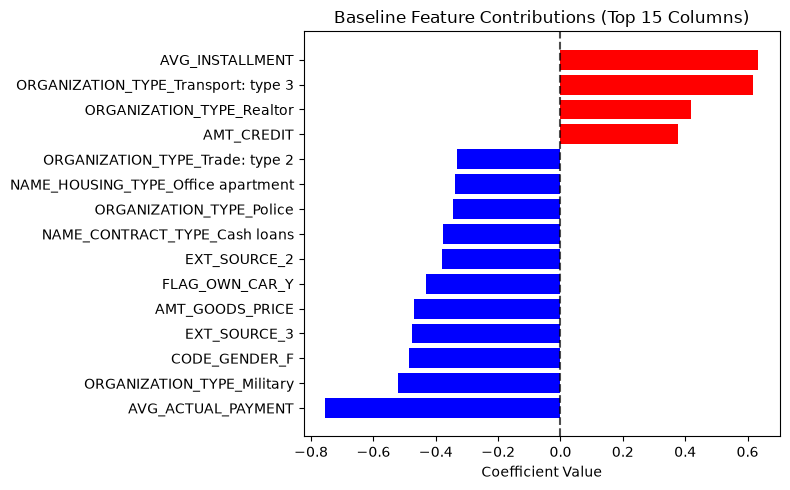

In [8]:
lr_coefficients = coefficient_table(lr_model)

# grab the top 15 features with the highest absolute weights and sort them
top_lr = lr_coefficients.head(15).sort_values("coefficient")

# assign red to features that increase default risk and blue to those that decrease it
colors = ["red" if x > 0 else "blue" for x in top_lr["coefficient"]]

# plot a clean horizontal bar chart
plt.figure(figsize=(8, 5))
plt.barh(top_lr["feature"], top_lr["coefficient"], color=colors)
plt.axvline(0, color="black", linestyle="--", alpha=0.7)
plt.xlabel("Coefficient Value")
plt.title("Baseline Feature Contributions (Top 15 Columns)")
plt.tight_layout()
plt.show()


## LightGBM

LightGBM is used as a nonlinear challenger to the Logistic Regression model.

Unlike Logistic Regression, the numerical variables do not need to be standardised and the model can also capture nonlinear relationships and interactions between features automatically.

In [9]:
lgbm_model = fit_lightgbm(X_train, y_train)
p_train_lgbm = predict_lightgbm(lgbm_model, X_train)
p_test_lgbm = predict_lightgbm(lgbm_model, X_test)

lgbm_results = evaluate_model(y_train, p_train_lgbm, y_test, p_test_lgbm)
print("LightGBM Metrics:")
print(pd.Series(lgbm_results).round(4))


LightGBM Metrics:
Train AUC     0.8518
Test AUC      0.7732
Test KS       0.4095
Test Brier    0.0666
dtype: float64


In [10]:
from imblearn.over_sampling import RandomOverSampler

# 1. Train the oversampled LightGBM model using your working function
ros = RandomOverSampler(random_state=10)
X_train_ros, y_train_ros = ros.fit_resample(X_train, y_train)

lgbm_oversample = fit_lightgbm(X_train_ros, y_train_ros)
p_train_lgb_os = predict_lightgbm(lgbm_oversample, X_train_ros)
p_test_lgb_os = predict_lightgbm(lgbm_oversample, X_test)
lgbm_os_results = evaluate_model(y_train_ros, p_train_lgb_os, y_test, p_test_lgb_os)

# 2. Combine the baseline and oversampled results into a clean comparison table
lgbm_comp_df = pd.DataFrame([{"Model": "LightGBM Baseline", **lgbm_results}, 
                             {"Model": "Oversampled LightGBM", **lgbm_os_results}]).set_index("Model")

print(lgbm_comp_df.round(4))


                      Train AUC  Test AUC  Test KS  Test Brier
Model                                                         
LightGBM Baseline        0.8518    0.7732   0.4095      0.0666
Oversampled LightGBM     0.8553    0.7740   0.4145      0.1736


## Feature Importance

Feature importance gives a first view of which variables LightGBM relies on most heavily.

This is useful as a model sense check: I would want the strongest features to be understandable, relevant to the lending problem and not potential sources of leakage.

However, feature importance does not show whether a feature increases or decreases predicted Default risk. For that I use SHAP.

,feature,importance
81,CREDIT_ANNUITY_RATIO,891
36,EXT_SOURCE_2,610
37,EXT_SOURCE_3,544
77,AGE_YEARS,503
89,BUREAU_AVG_DAYS_CREDIT,472
78,EMPLOYMENT_YEARS,452
98,AVG_ACTUAL_PAYMENT,445
16,DAYS_ID_PUBLISH,445
86,BUREAU_AVG_CREDIT,411
82,GOODS_CREDIT_RATIO,409


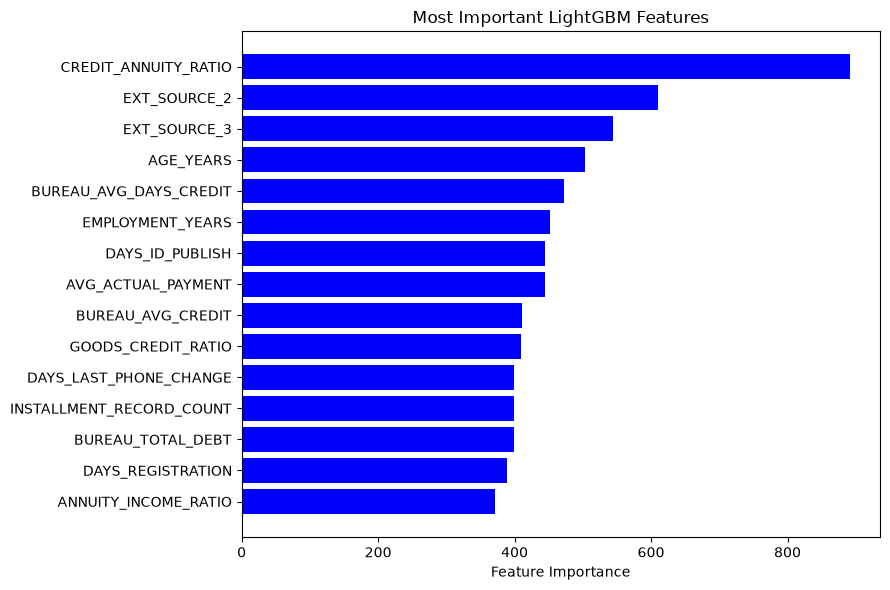

In [11]:
lgbm_importance = feature_importance_table(lgbm_model)

display(lgbm_importance.head(15))
top_features = lgbm_importance.head(15).sort_values("importance")

plt.figure(figsize=(9, 6))
plt.barh(top_features["feature"],top_features["importance"],color="blue")

plt.xlabel("Feature Importance")
plt.title("Most Important LightGBM Features")
plt.tight_layout()
plt.show()

### SHAP Interpretation

SHAP gives more information than the native lightgbm feature-importance ranking.

The summary plot shows which features contribute most strongly across the sample and whether different feature values tend to push predicted Default risk higher or lower.

The individual explanation shows how the model moves from its baseline prediction to the predicted Default probability for one applicant.

While for a regulated model this would only form part of the explanation, this is still very informative to better understand the model's decision.
While for a true model interpretation, I would also want to understand the model's calibration, stability, sensitivity and data lineage before relying on it in practice.

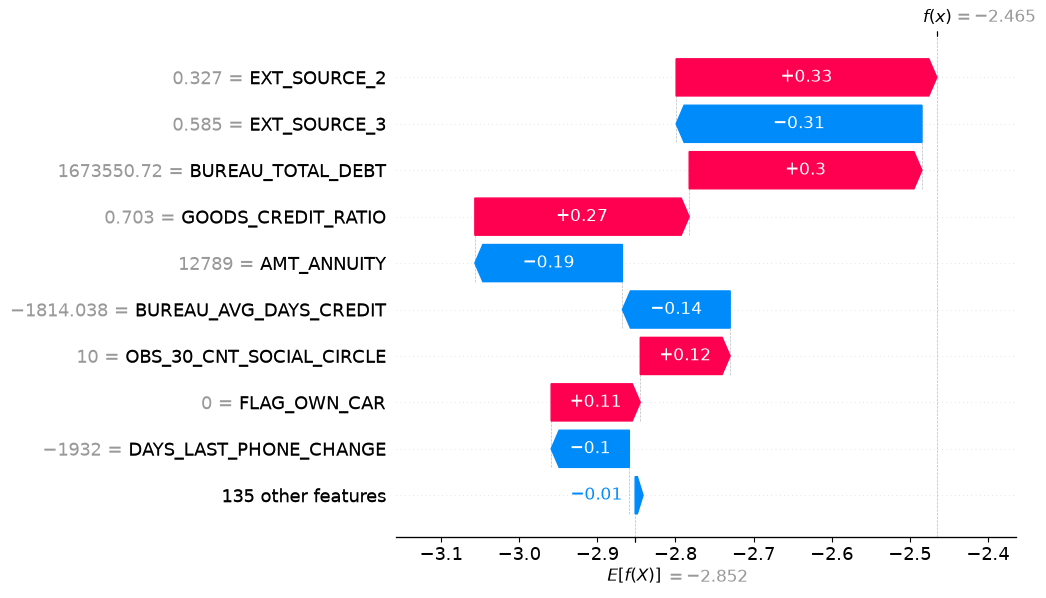

Applicant ID: 366345
Predicted Default probability: 0.0783


In [16]:
import shap

X_test_lgb = transform_lightgbm_data(lgbm_model, X_test)
X_shap = X_test_lgb.sample(n=min(2000, len(X_test_lgb)), random_state=10)

explainer = shap.TreeExplainer(lgbm_model)
shap_values = explainer(X_shap)

#shap.plots.beeswarm(shap_values)

shap.plots.waterfall(shap_values[0])

app_idx = X_shap.index[0]
app_prob = predict_lightgbm(lgbm_model, X_test.loc[[app_idx]])[0]

print(f"Applicant ID: {id_test.loc[app_idx]}")
print(f"Predicted Default probability: {app_prob:.4f}")


## LightGBM Interpretation

Feature importance shows that LightGBM relies heavily on affordability, external credit scores and historical credit information, particularly `CREDIT_ANNUITY_RATIO`, `EXT_SOURCE_2` and `EXT_SOURCE_3`.

SHAP adds direction to this: lower `EXT_SOURCE_2` values tend to increase predicted Default risk, while higher values reduce it. For the example applicant, lower `EXT_SOURCE_2`, higher bureau debt and `GOODS_CREDIT_RATIO` push the prediction upwards, while `EXT_SOURCE_3` and annuity reduce it.

This broadly agrees with the Logistic Regression, where the external credit scores also appeared as important risk-reducing features. Overall, feature importance shows **what the model relies on**, while SHAP helps explain **how those features affect the prediction**.

## Neural Network

Neural Networks provides our second nonlinear challenger to the base Logistic Regression model.

Numerical features are standardised and categorical features are one-hot encoded. The model uses two hidden layers with 128 and 64 neurons, ReLU activation and dropout to reduce overfitting.

Unlike Logistic Regression, the internal parameters are not directly interpretable, so I the model is mainly used for comparison of its predictive performance and generalisation.

In [35]:
nn_model = fit_neural_network(X_train, y_train, epochs=10)
p_train_nn = predict_neural_network(nn_model, X_train)
p_test_nn = predict_neural_network(nn_model, X_test)

nn_results = evaluate_model(y_train, p_train_nn, y_test, p_test_nn)
display(pd.Series(nn_results))


epoch: 1 - train loss: 0.2802 - val auc: 0.7387
epoch: 2 - train loss: 0.2520 - val auc: 0.7427
epoch: 3 - train loss: 0.2515 - val auc: 0.7453
epoch: 4 - train loss: 0.2501 - val auc: 0.7458
epoch: 5 - train loss: 0.2495 - val auc: 0.7475
epoch: 6 - train loss: 0.2482 - val auc: 0.7462
epoch: 7 - train loss: 0.2474 - val auc: 0.7487
epoch: 8 - train loss: 0.2464 - val auc: 0.7486
epoch: 9 - train loss: 0.2453 - val auc: 0.7494
epoch: 10 - train loss: 0.2445 - val auc: 0.7502


Train AUC     0.776112
Test AUC      0.758568
Test KS       0.383449
Test Brier    0.067737
dtype: float64

## Neural Network Interpretation

The Neural Network provides a modest improvement over Logistic Regression but does not match LightGBM's Test performance.

Its AUC difference is also much smaller than LightGBM's, suggesting better generalisation for this specific implementation.

However, the model is less interpretable than Logistic Regression and lightgbm, so the additional performance would need to justify the added complexity. And in this instance, it is not justifiable.

# Final Comparison

In [36]:
results = pd.DataFrame([{"Model": "Logistic Regression", **lr_results},
                        {"Model": "LightGBM", **lgbm_results},
                        {"Model": "Neural Network", **nn_results}])

display(results.round(4))

,Model,Train AUC,Test AUC,Test KS,Test Brier
0,Logistic Regression,0.7531,0.7518,0.3745,0.0682
1,LightGBM,0.8518,0.7732,0.4095,0.0666
2,Neural Network,0.7761,0.7586,0.3834,0.0677


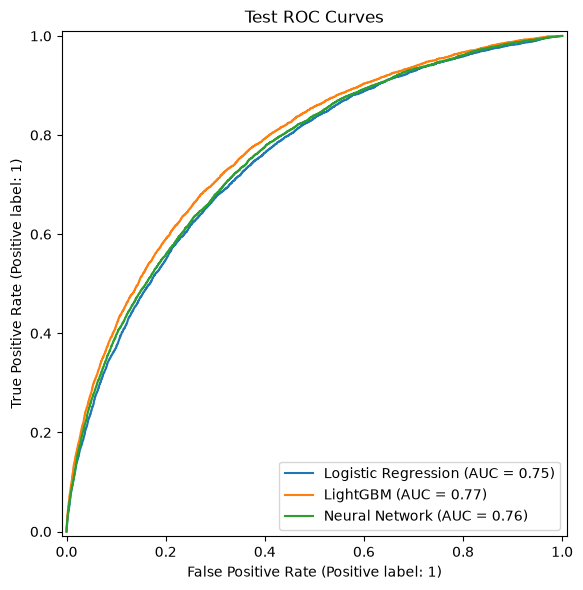

In [42]:
fig, ax = plt.subplots(figsize=(7, 6))

# Plot ROC curves
models = [("Logistic Regression", p_test_lr), ("LightGBM", p_test_lgbm), ("Neural Network", p_test_nn)]
for name, preds in models:
    RocCurveDisplay.from_predictions(y_test, preds, name=name, ax=ax)

plt.title("Test ROC Curves")
plt.tight_layout()
plt.show()


## Model Comparison and Judgement

The three models show a clear trade-off between predictive performance, generalisation and interpretability.

**Logistic Regression** provides the most transparent benchmark and shows almost identical Train and Test performance. Its coefficients and odds ratios allow the model relationships to be inspected directly.

**LightGBM** provides the strongest Test discrimination and lowest Brier score, suggesting that nonlinear relationships and interactions contain additional predictive information. However, it also has the largest Train/Test performance gap, indicating greater overfitting. Feature importance and SHAP help explain its predictions, but the model remains less transparent than Logistic Regression.

**Neural Network** provides a modest improvement over Logistic Regression and generalises better than the current LightGBM specification, but does not achieve the same Test discrimination and is less directly interpretable.

Class weighting and oversampling provided little improvement in discrimination and substantially worsened probability quality, so I retain the original class distribution.

For a real lending model I would not select a model from AUC alone. I would also consider calibration, stability, interpretability, sensitivity, data lineage and performance over time before model selection.